In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Cell 0 (code)

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/joy11117/sentigold-data-for-fine-tuning/sentigold_sample.csv
/kaggle/input/datasets/joy11117/sentigold-data-for-fine-tuning/sentigold_sample.jsonl


Cell 1 — Setup + Bangla Font Fix (কোনো figure না, শুধু prep)

In [2]:
# ============================================================
# CELL 1 — MASTER SETUP + BANGLA FONT FIX
# ============================================================
import os, urllib.request
from pathlib import Path

ROOT      = Path("/kaggle/working")
PROCESSED = ROOT / "processed"
MODELS    = ROOT / "models"
OUTPUTS   = ROOT / "outputs"
FIGS      = ROOT / "figures"          # thesis figures এখানে জমা হবে
for f in [PROCESSED, MODELS, OUTPUTS, FIGS]:
    f.mkdir(parents=True, exist_ok=True)

# ── Advisor fix #1: prevent duplicate figures on re-runs ──────────────────
# Previously, re-running a cell (e.g. Cell 6 / BanglaBERT) in the same kernel session
# kept incrementing the global fig_count instead of overwriting, producing duplicate
# plots (fig17-19 AND fig20-22 for the same three BanglaBERT charts). Wiping the
# figures folder at the very start of every run guarantees each figure is generated
# exactly once, as long as you use "Run All" from the top instead of re-running
# individual cells out of order.
import json

for old_fig in FIGS.glob("*.png"):
    old_fig.unlink()
print("✓ Figures folder cleared — starting a fresh, single numbering run")

# ── Advisor fix #5: helper to persist exact numeric results (not just chart pixels) ──
def save_json(obj, path):
    """Save a dict/list of results to disk as pretty JSON so exact numbers can be
    cited in the paper/report, not just read off a bar chart."""
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, ensure_ascii=False, indent=2)
    print(f"✓ Saved JSON: {path}")

# ⚠️ আসল সঠিক path (screenshot থেকে হুবহু)
RAW = Path("/kaggle/input/datasets/joy11117/sentigold-data-for-fine-tuning/sentigold_sample.csv")

os.system("pip install transformers==4.40.0 wordcloud -q")

# ── Bangla font download (matplotlib/wordcloud-এ বাংলা লেখা ঠিকভাবে দেখানোর জন্য) ──
FONT_PATH = ROOT / "NotoSansBengali-Regular.ttf"
if not FONT_PATH.exists():
    url = "https://raw.githubusercontent.com/notofonts/noto-fonts/main/hinted/ttf/NotoSansBengali/NotoSansBengali-Regular.ttf"
    urllib.request.urlretrieve(url, FONT_PATH)

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont(str(FONT_PATH))
bn_font = fm.FontProperties(fname=str(FONT_PATH))
plt.rcParams["axes.unicode_minus"] = False

import torch
print("✓ Setup done")
print("✓ GPU available:", torch.cuda.is_available())
print("✓ Bangla font ready:", FONT_PATH.exists())

# ── path ঠিক আছে কিনা যাচাই ──
if RAW.exists():
    print("✓ Dataset found at:", RAW)
else:
    print("✗ Dataset NOT found — path ভুল আছে, ডানপাশের Input panel থেকে exact path আবার চেক করুন")

✓ Figures folder cleared — starting a fresh, single numbering run
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 62.8 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.40.0 which is incompatible.


✓ Setup done
✓ GPU available: True
✓ Bangla font ready: True
✓ Dataset found at: /kaggle/input/datasets/joy11117/sentigold-data-for-fine-tuning/sentigold_sample.csv


Cell 2 — Load Data + EDA Figures (Figure 1–6)

✓ Loaded: (70000, 4)
Polarity
SP    15318
NU    15156
SN    13767
WN    13682
WP    12077
Name: count, dtype: int64


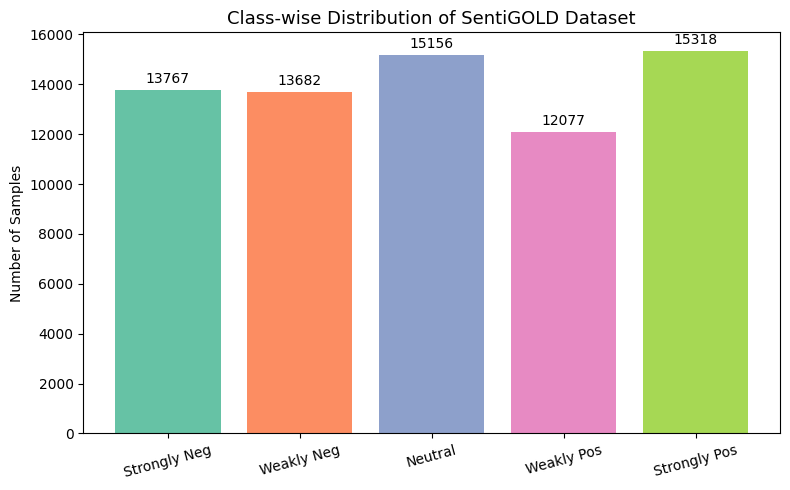

✓ Saved: fig01_class_distribution.png


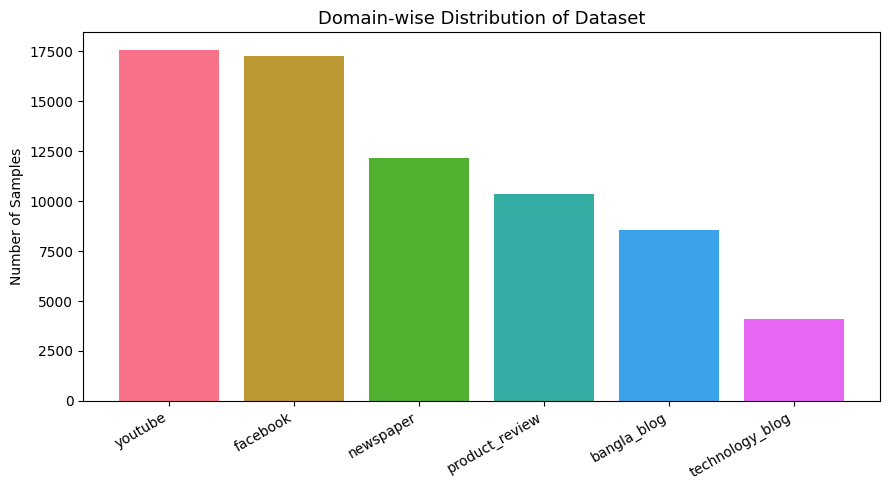

✓ Saved: fig02_domain_distribution.png


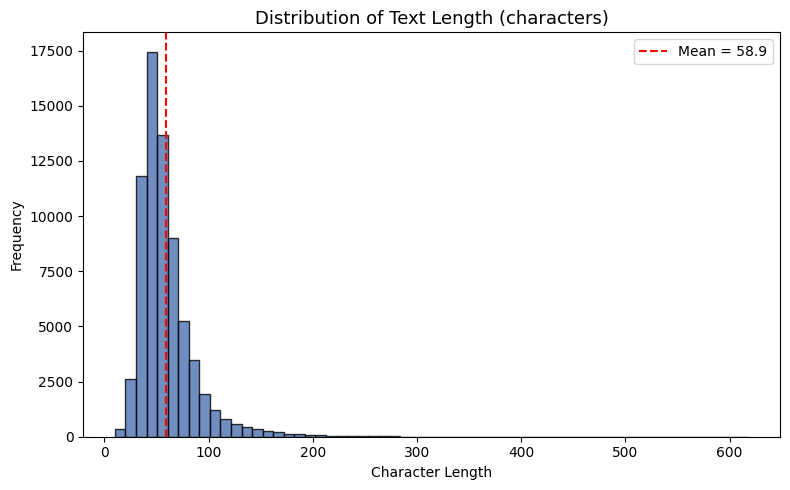

✓ Saved: fig03_text_length_distribution.png


/tmp/ipykernel_58/1290919984.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df["Polarity"].map(LABEL2ID).map(dict(enumerate(CLASS_NAMES))),


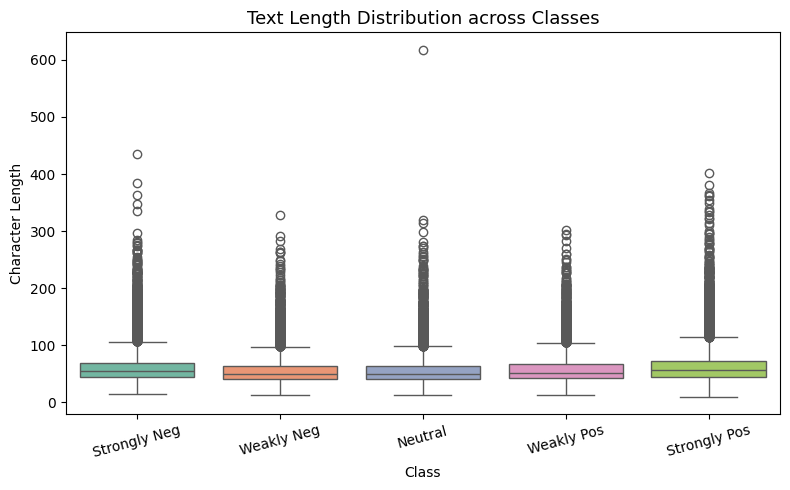

✓ Saved: fig04_textlen_by_class.png


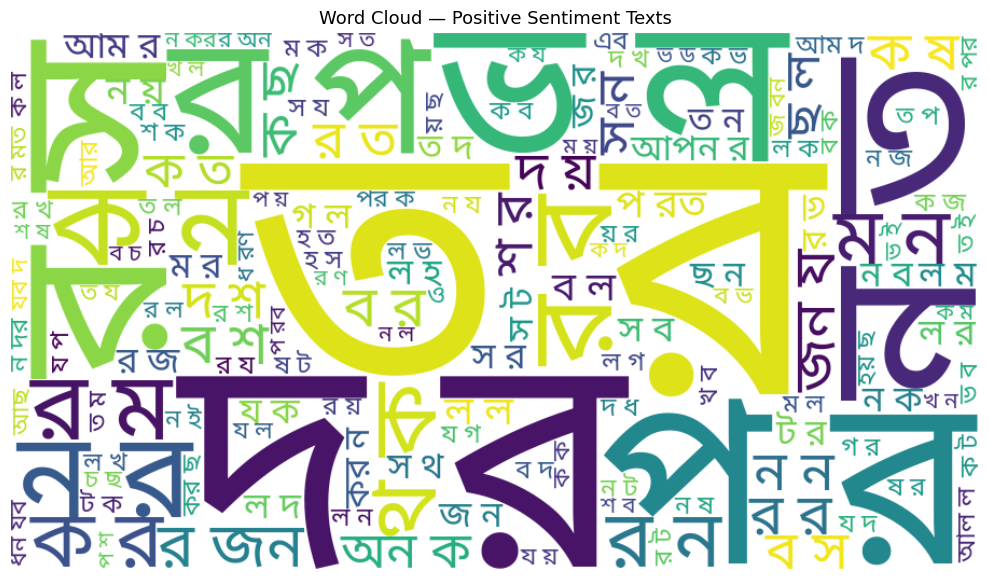

✓ Saved: fig05_wordcloud_positive.png


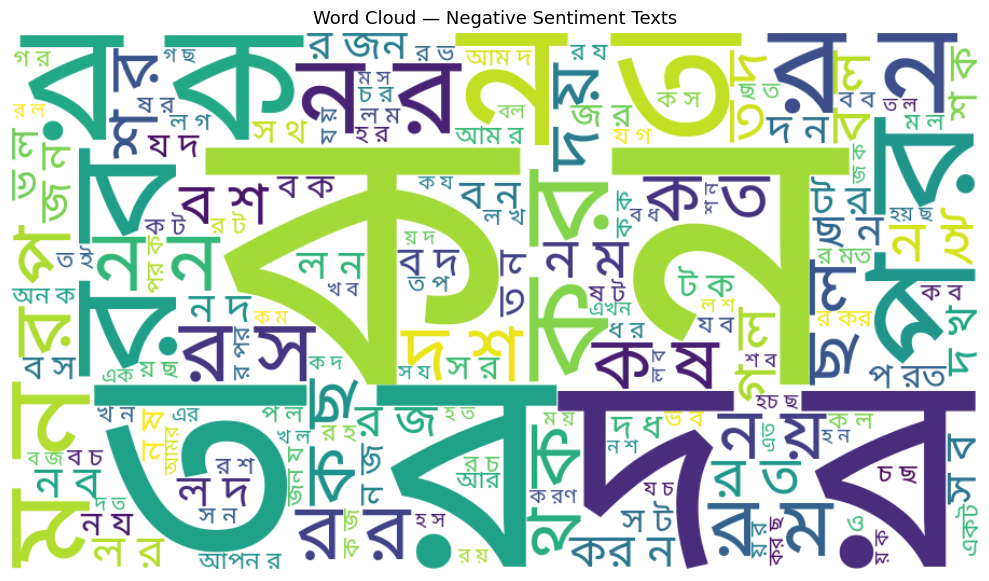

✓ Saved: fig06_wordcloud_negative.png

✓ Total figures so far: 6


In [3]:
# ============================================================
# CELL 2 — DATA LOAD + EXPLORATORY DATA ANALYSIS (Fig 1-6)
# ============================================================
import pandas as pd
import numpy as np
import seaborn as sns
from wordcloud import WordCloud

LABEL2ID    = {"SN": 0, "WN": 1, "NU": 2, "WP": 3, "SP": 4}
CLASS_NAMES = ["Strongly Neg", "Weakly Neg", "Neutral", "Weakly Pos", "Strongly Pos"]
COLORS      = sns.color_palette("Set2", 5)

df = pd.read_csv(RAW)
# Advisor fix #2: keep ID + Domain columns so "Fig 2: Domain Distribution" below
# actually has data to plot, and so Domain survives into train/valid/test splits
# for the Domain-wise Performance figure later (no more end-of-notebook patch cell needed).
keep_cols = [c for c in ["ID", "Text", "Domain", "Polarity"] if c in df.columns]
df = df[keep_cols].dropna(subset=["Text", "Polarity"])
df["Text"] = df["Text"].astype(str)
print("✓ Loaded:", df.shape)
print(df["Polarity"].value_counts())

fig_count = 0
def savefig(name):
    global fig_count
    fig_count += 1
    path = FIGS / f"fig{fig_count:02d}_{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"✓ Saved: {path.name}")

# ---- Fig 1: Class Distribution ----
counts = df["Polarity"].map(LABEL2ID).value_counts().sort_index()
plt.figure(figsize=(8,5))
bars = plt.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color=COLORS)
for b,v in zip(bars, counts.values):
    plt.text(b.get_x()+b.get_width()/2, v+300, str(v), ha="center", fontsize=10)
plt.title("Class-wise Distribution of SentiGOLD Dataset", fontsize=13)
plt.ylabel("Number of Samples")
plt.xticks(rotation=15)
savefig("class_distribution")

# ---- Fig 2: Domain Distribution ----
plt.figure(figsize=(9,5))
dom = df["Domain"].value_counts() if "Domain" in df.columns else None
if dom is not None:
    bars = plt.bar(dom.index, dom.values, color=sns.color_palette("husl", len(dom)))
    plt.title("Domain-wise Distribution of Dataset", fontsize=13)
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=30, ha="right")
    savefig("domain_distribution")

# ---- Fig 3: Text Length Histogram ----
df["text_len"] = df["Text"].apply(len)
plt.figure(figsize=(8,5))
plt.hist(df["text_len"], bins=60, color="#4C72B0", edgecolor="black", alpha=0.8)
plt.axvline(df["text_len"].mean(), color="red", linestyle="--", label=f"Mean = {df['text_len'].mean():.1f}")
plt.title("Distribution of Text Length (characters)", fontsize=13)
plt.xlabel("Character Length")
plt.ylabel("Frequency")
plt.legend()
savefig("text_length_distribution")

# ---- Fig 4: Text Length by Class (Boxplot) ----
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Polarity"].map(LABEL2ID).map(dict(enumerate(CLASS_NAMES))),
            y=df["text_len"], order=CLASS_NAMES, palette="Set2")
plt.title("Text Length Distribution across Classes", fontsize=13)
plt.xlabel("Class")
plt.ylabel("Character Length")
plt.xticks(rotation=15)
savefig("textlen_by_class")

# ---- Fig 5: WordCloud — Positive Classes ----
pos_text = " ".join(df[df["Polarity"].isin(["WP","SP"])]["Text"].tolist())
wc_pos = WordCloud(width=900, height=500, background_color="white",
                    font_path=str(FONT_PATH), max_words=150).generate(pos_text)
plt.figure(figsize=(10,6))
plt.imshow(wc_pos, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Positive Sentiment Texts", fontsize=13)
savefig("wordcloud_positive")

# ---- Fig 6: WordCloud — Negative Classes ----
neg_text = " ".join(df[df["Polarity"].isin(["WN","SN"])]["Text"].tolist())
wc_neg = WordCloud(width=900, height=500, background_color="white",
                    font_path=str(FONT_PATH), max_words=150).generate(neg_text)
plt.figure(figsize=(10,6))
plt.imshow(wc_neg, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Negative Sentiment Texts", fontsize=13)
savefig("wordcloud_negative")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 3 — Preprocessing + Train/Val/Test Split (Figure 7–8)

Train: 61,270 | Valid: 7,000 | Test: 7,000


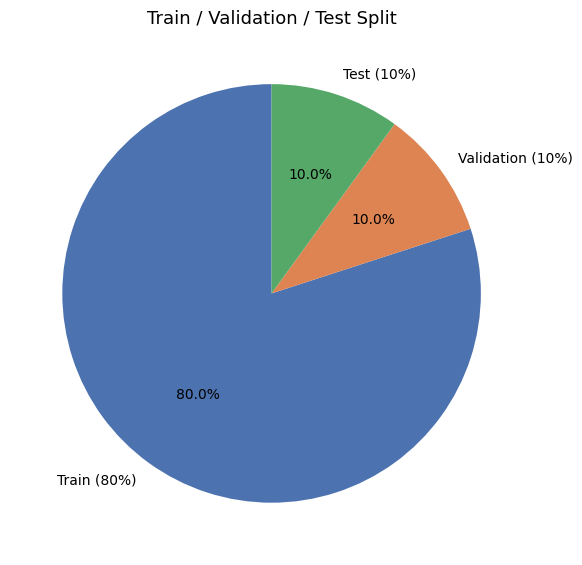

✓ Saved: fig07_train_val_test_split.png


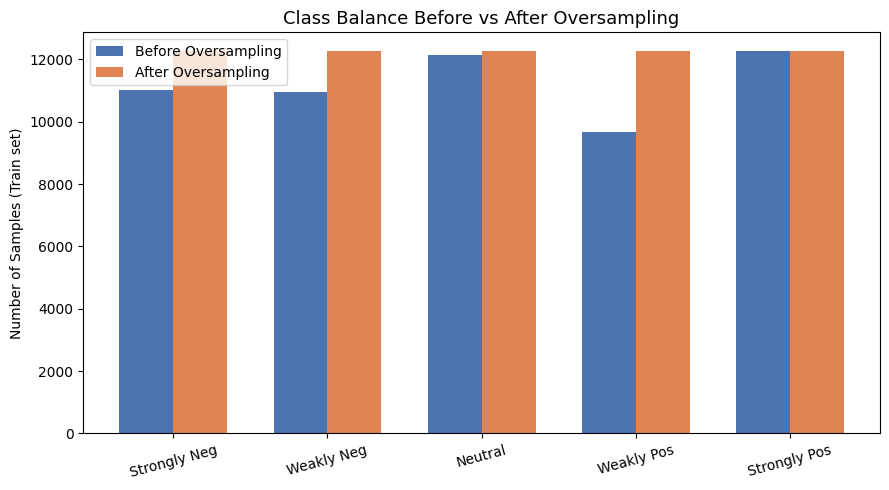

✓ Saved: fig08_oversampling_before_after.png

✓ Total figures so far: 8


In [4]:
# ============================================================
# CELL 3 — PREPROCESSING + SPLIT (Fig 7-8)
# ============================================================
import re, unicodedata
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler

SEED = 42

def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text))
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["Text"] = df["Text"].apply(normalize_text)
df = df[df["Text"].str.len() > 0]
df = df[df["Polarity"].isin(LABEL2ID.keys())]
df["label"] = df["Polarity"].map(LABEL2ID)
df = df.reset_index(drop=True)

train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
valid_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)

before_counts = train_df["Polarity"].value_counts().reindex(LABEL2ID.keys())

# ── oversample TRAIN ONLY (কোনো data leakage নেই, rule মেনে) ──
ros = RandomOverSampler(random_state=SEED)
X_res, y_res = ros.fit_resample(train_df[["Text"]], train_df["label"])
train_bal = pd.DataFrame({
    "Text": X_res["Text"],
    "Polarity": y_res.map({v:k for k,v in LABEL2ID.items()}),
    "label": y_res
})
after_counts = train_bal["Polarity"].value_counts().reindex(LABEL2ID.keys())

train_bal.to_csv(PROCESSED/"train.csv", index=False)
valid_df.to_csv(PROCESSED/"valid.csv", index=False)
test_df.to_csv(PROCESSED/"test.csv", index=False)

print(f"Train: {len(train_bal):,} | Valid: {len(valid_df):,} | Test: {len(test_df):,}")

# ---- Fig 7: Split Proportion Pie ----
plt.figure(figsize=(6,6))
plt.pie([len(train_df), len(valid_df), len(test_df)],
        labels=["Train (80%)","Validation (10%)","Test (10%)"],
        autopct="%1.1f%%", colors=["#4C72B0","#DD8452","#55A868"], startangle=90)
plt.title("Train / Validation / Test Split", fontsize=13)
savefig("train_val_test_split")

# ---- Fig 8: Before vs After Oversampling ----
x = np.arange(5)
width = 0.35
plt.figure(figsize=(9,5))
plt.bar(x-width/2, before_counts.values, width, label="Before Oversampling", color="#4C72B0")
plt.bar(x+width/2, after_counts.values, width, label="After Oversampling", color="#DD8452")
plt.xticks(x, CLASS_NAMES, rotation=15)
plt.ylabel("Number of Samples (Train set)")
plt.title("Class Balance Before vs After Oversampling", fontsize=13)
plt.legend()
savefig("oversampling_before_after")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 4 — ML Branch: TF-IDF + Random Forest + XGBoost (Figure 9–13)

RF  : {'accuracy': 0.4855714285714286, 'precision_macro': 0.4853343990685544, 'recall_macro': 0.476308847646815, 'f1_macro': 0.47427953991753063}
XGB : {'accuracy': 0.5017142857142857, 'precision_macro': 0.5000754338496577, 'recall_macro': 0.49552744008340177, 'f1_macro': 0.4960935955335316}


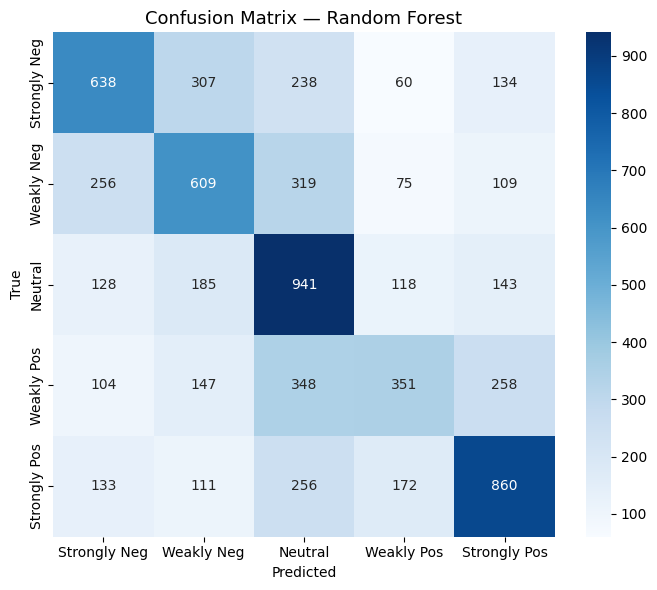

✓ Saved: fig09_cm_random_forest.png


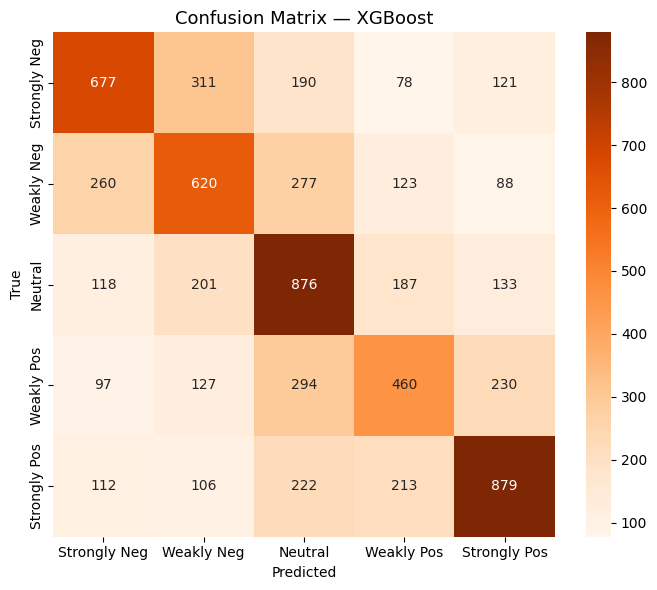

✓ Saved: fig10_cm_xgboost.png


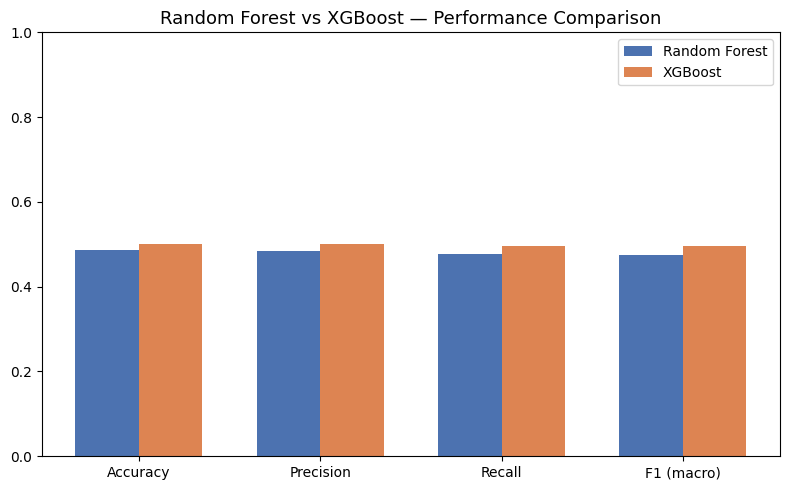

✓ Saved: fig11_ml_models_comparison.png


/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 99 (c) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 104 (h) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 97 (a) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 114 (r) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 119 (w) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 111 (o) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipyke

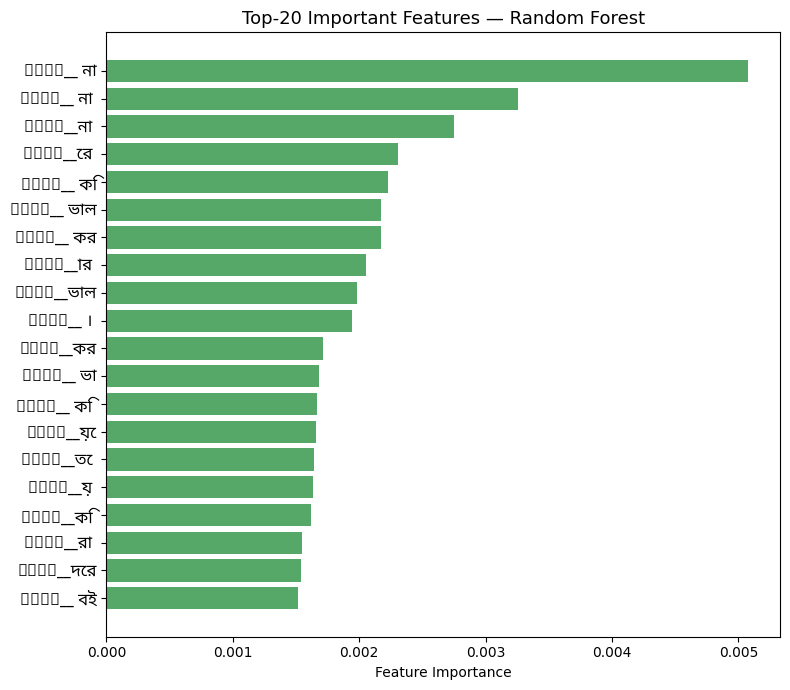

✓ Saved: fig12_rf_feature_importance.png


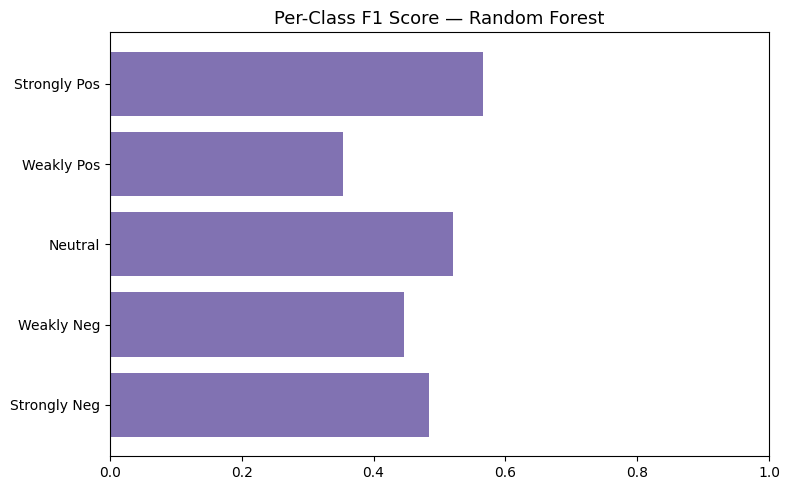

✓ Saved: fig13_rf_per_class_f1.png

✓ Total figures so far: 13


In [5]:
# ============================================================
# CELL 4 — ML BRANCH: TF-IDF + RF + XGBoost (Fig 9-13)
# ============================================================
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix)

def metrics_dict(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true,y_pred),
        "precision_macro": precision_score(y_true,y_pred,average="macro",zero_division=0),
        "recall_macro": recall_score(y_true,y_pred,average="macro",zero_division=0),
        "f1_macro": f1_score(y_true,y_pred,average="macro",zero_division=0),
    }

train_bal = pd.read_csv(PROCESSED/"train.csv")
valid_df  = pd.read_csv(PROCESSED/"valid.csv")
test_df   = pd.read_csv(PROCESSED/"test.csv")

# ── Advisor fix #3: strengthen the classical ML baseline ──────────────────
# With the true held-out test set, plain word TF-IDF was quite weak (F1 ~0.36-0.37).
# Two changes that usually help TF-IDF baselines on fine-grained Bangla sentiment:
#   1) add character (3-5)-gram TF-IDF alongside word (1-2)-grams — captures
#      subword/morphological cues (prefixes/suffixes, spelling variation) that a
#      pure word-level vectorizer misses in Bangla;
#   2) class-balanced weighting, since RF/XGB were treating all 5 classes equally
#      even though the raw class sizes are skewed.
# NOTE: this doesn't fully close the gap with BanglaBERT — see the Discussion
# section for an honest limitations note (TF-IDF simply can't capture the
# contextual/semantic cues a transformer can on 5-class fine-grained sentiment).
from sklearn.pipeline import FeatureUnion
from sklearn.utils.class_weight import compute_sample_weight

word_tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), sublinear_tf=True)
char_tfidf = TfidfVectorizer(max_features=20000, ngram_range=(3,5), analyzer="char_wb", sublinear_tf=True)
tfidf = FeatureUnion([("word", word_tfidf), ("char", char_tfidf)])

X_train = tfidf.fit_transform(train_bal["Text"])
X_valid = tfidf.transform(valid_df["Text"])
X_test  = tfidf.transform(test_df["Text"])
y_train = train_bal["label"].values
y_valid = valid_df["Polarity"].map(LABEL2ID).values
y_test  = test_df["Polarity"].map(LABEL2ID).values

rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                             class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred_test = rf.predict(X_test)
rf_metrics = metrics_dict(y_test, rf_pred_test)

xgb_sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)
xgb = XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8, min_child_weight=1,
                     objective="multi:softprob", eval_metric="mlogloss", random_state=SEED)
xgb.fit(X_train, y_train, sample_weight=xgb_sample_weight)
xgb_pred_test = xgb.predict(X_test)
xgb_metrics = metrics_dict(y_test, xgb_pred_test)

P_ML_valid = (rf.predict_proba(X_valid) + xgb.predict_proba(X_valid)) / 2  # RF+XGB averaged → fusion-এ ব্যবহার হবে
P_ML_test  = (rf.predict_proba(X_test)  + xgb.predict_proba(X_test))  / 2
np.save(OUTPUTS/"P_ML_valid.npy", P_ML_valid)
np.save(OUTPUTS/"P_ML_test.npy", P_ML_test)
joblib.dump({"bundle":tfidf,"model":rf}, MODELS/"rf_tfidf.joblib")
joblib.dump({"bundle":tfidf,"model":xgb}, MODELS/"xgb_tfidf.joblib")

print("RF  :", rf_metrics)
print("XGB :", xgb_metrics)

# ---- Fig 9: RF Confusion Matrix ----
cm_rf = confusion_matrix(y_test, rf_pred_test)
plt.figure(figsize=(7,6))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — Random Forest", fontsize=13)
plt.xlabel("Predicted"); plt.ylabel("True")
savefig("cm_random_forest")

# ---- Fig 10: XGBoost Confusion Matrix ----
cm_xgb = confusion_matrix(y_test, xgb_pred_test)
plt.figure(figsize=(7,6))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Oranges", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — XGBoost", fontsize=13)
plt.xlabel("Predicted"); plt.ylabel("True")
savefig("cm_xgboost")

# ---- Fig 11: RF vs XGBoost Comparison ----
metric_names = ["accuracy","precision_macro","recall_macro","f1_macro"]
rf_vals  = [rf_metrics[m] for m in metric_names]
xgb_vals = [xgb_metrics[m] for m in metric_names]
x = np.arange(len(metric_names)); width=0.35
plt.figure(figsize=(8,5))
plt.bar(x-width/2, rf_vals, width, label="Random Forest", color="#4C72B0")
plt.bar(x+width/2, xgb_vals, width, label="XGBoost", color="#DD8452")
plt.xticks(x, ["Accuracy","Precision","Recall","F1 (macro)"])
plt.ylim(0,1)
plt.title("Random Forest vs XGBoost — Performance Comparison", fontsize=13)
plt.legend()
savefig("ml_models_comparison")

# ---- Fig 12: RF Top-20 Feature Importance (Bangla words, font fixed) ----
importances = rf.feature_importances_
top_idx = np.argsort(importances)[-20:]
feat_names = np.array(tfidf.get_feature_names_out())[top_idx]
plt.figure(figsize=(8,7))
plt.barh(feat_names, importances[top_idx], color="#55A868")
plt.yticks(fontproperties=bn_font, fontsize=12)
plt.title("Top-20 Important Features — Random Forest", fontsize=13)
plt.xlabel("Feature Importance")
savefig("rf_feature_importance")

# ---- Fig 13: Precision/Recall/F1 per class — RF ----
from sklearn.metrics import classification_report
rep = classification_report(y_test, rf_pred_test, target_names=CLASS_NAMES, output_dict=True)
pcf1 = [rep[c]["f1-score"] for c in CLASS_NAMES]
plt.figure(figsize=(8,5))
plt.barh(CLASS_NAMES, pcf1, color="#8172B2")
plt.xlim(0,1)
plt.title("Per-Class F1 Score — Random Forest", fontsize=13)
savefig("rf_per_class_f1")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 5 — DL Branch: FastText + CNN-BiLSTM-Attention (Figure 14–17)

FastText coverage: 19976/30002 tokens
Epoch 01 | loss 1.3042 | val F1 0.4990 | val acc 0.5051
Epoch 02 | loss 0.9916 | val F1 0.5154 | val acc 0.5271
Epoch 03 | loss 0.7581 | val F1 0.5095 | val acc 0.5144
Epoch 04 | loss 0.5592 | val F1 0.5022 | val acc 0.5073
Epoch 05 | loss 0.3863 | val F1 0.4837 | val acc 0.4939
Early stopping


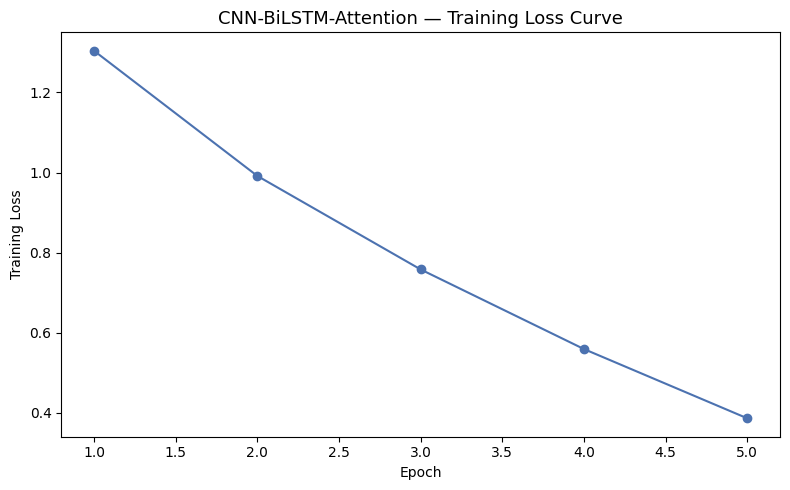

✓ Saved: fig14_dl_training_loss.png


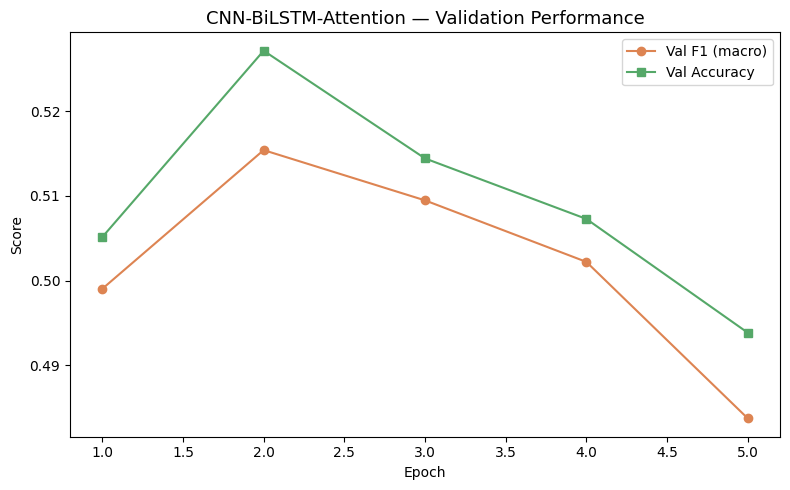

✓ Saved: fig15_dl_validation_curve.png


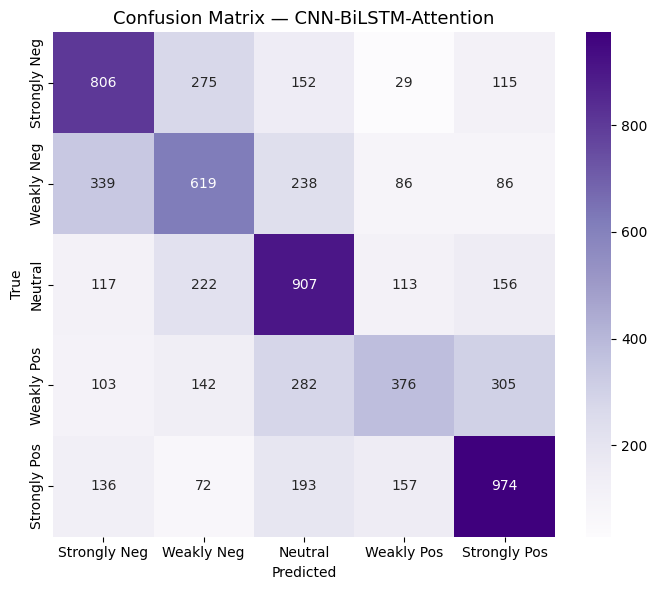

✓ Saved: fig16_cm_cnn_bilstm.png


/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:28: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_58/1290919984.py:29: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Bengali.
  plt.savefig(path, dpi=200, bbox_inches="tight")
/tmp/ipykernel_58/1290919984.py:29: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Bengali.
  plt.savefig(path, dpi=200, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Bengali.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Bengali.
  fig.canvas.print_figure(bytes_io, **kw)


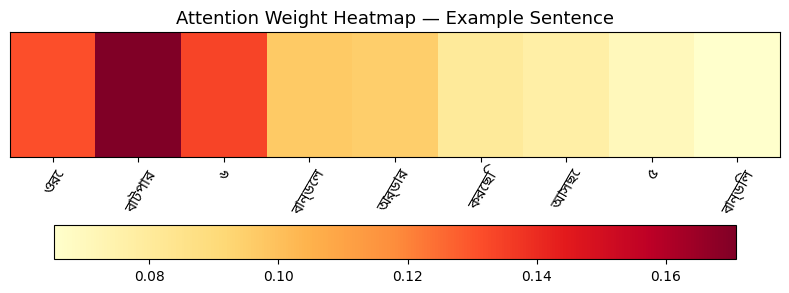

✓ Saved: fig17_attention_heatmap_example.png

✓ Total figures so far: 17


In [6]:
# ============================================================
# CELL 5 — DL BRANCH: CNN-BiLSTM-Attention (Fig 14-17)
# ============================================================
import torch, torch.nn as nn, torch.nn.functional as F, urllib.request
from torch.utils.data import Dataset, DataLoader
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── FastText embedding download (একবারই) ──
FT_PATH = ROOT / "wiki.bn.vec"
if not FT_PATH.exists():
    print("Downloading Bangla FastText vectors...")
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.bn.vec", FT_PATH)

# ── vocab build ──
def tokenize(t): return t.split()
counter = Counter()
for t in train_bal["Text"]: counter.update(tokenize(t))
vocab = {"<pad>":0, "<unk>":1}
for w,_ in counter.most_common(30000): vocab[w] = len(vocab)

def encode(text, max_len=64):
    ids = [vocab.get(w,1) for w in tokenize(text)][:max_len]
    ids += [0]*(max_len-len(ids))
    return ids

class SentiDS(Dataset):
    def __init__(self, texts, labels):
        self.X = [encode(t) for t in texts]
        self.y = labels
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return torch.tensor(self.X[i]), torch.tensor(self.y[i])

train_ds = SentiDS(train_bal["Text"].tolist(), train_bal["label"].tolist())
valid_ds = SentiDS(valid_df["Text"].tolist(), y_valid.tolist())
test_ds  = SentiDS(test_df["Text"].tolist(), y_test.tolist())
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_ds, batch_size=128)
test_loader  = DataLoader(test_ds, batch_size=128)

# ── load FastText weights into embedding matrix ──
embed_dim = 300
emb_matrix = np.random.normal(0,0.1,(len(vocab), embed_dim)).astype(np.float32)
found = 0
with open(FT_PATH, encoding="utf-8") as f:
    next(f)
    for line in f:
        parts = line.rstrip().split(" ")
        w = parts[0]
        if w in vocab:
            emb_matrix[vocab[w]] = np.array(parts[1:], dtype=np.float32)
            found += 1
print(f"FastText coverage: {found}/{len(vocab)} tokens")

class CNNBiLSTMAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim=300, num_classes=5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.embedding.weight.data.copy_(torch.tensor(emb_matrix))
        self.conv = nn.Conv1d(embed_dim, 128, kernel_size=3, padding=1)
        self.lstm = nn.LSTM(128, 128, num_layers=2, batch_first=True,
                             bidirectional=True, dropout=0.3)
        self.attn = nn.Linear(256, 1)
        self.fc1 = nn.Linear(256, 64)
        self.fc2 = nn.Linear(64, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        e = self.embedding(x).permute(0,2,1)
        c = F.relu(self.conv(e)).permute(0,2,1)
        out,_ = self.lstm(c)
        attn_w = torch.softmax(self.attn(out).squeeze(-1), dim=1)
        context = torch.sum(out * attn_w.unsqueeze(-1), dim=1)
        h = self.dropout(F.relu(self.fc1(context)))
        return self.fc2(h), attn_w

model = CNNBiLSTMAttention(len(vocab)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

train_losses, val_f1s, val_accs = [], [], []
best_f1, patience, wait = 0, 3, 0

for epoch in range(15):
    model.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits, _ = model(xb)
        loss = criterion(logits, yb)
        loss.backward(); optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)

    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in valid_loader:
            logits, _ = model(xb.to(device))
            preds += logits.argmax(1).cpu().tolist()
            trues += yb.tolist()
    f1 = f1_score(trues, preds, average="macro")
    acc = accuracy_score(trues, preds)
    train_losses.append(avg_loss); val_f1s.append(f1); val_accs.append(acc)
    print(f"Epoch {epoch+1:02d} | loss {avg_loss:.4f} | val F1 {f1:.4f} | val acc {acc:.4f}")

    if f1 > best_f1:
        best_f1 = f1; wait = 0
        torch.save(model.state_dict(), MODELS/"cnn_bilstm_attention.pt")
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping"); break

model.load_state_dict(torch.load(MODELS/"cnn_bilstm_attention.pt"))
model.eval()

def get_probs(loader):
    all_probs = []
    with torch.no_grad():
        for xb,_ in loader:
            logits,_ = model(xb.to(device))
            all_probs.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(all_probs)

P_DL_valid = get_probs(valid_loader)
P_DL_test  = get_probs(test_loader)
np.save(OUTPUTS/"P_DL_valid.npy", P_DL_valid)
np.save(OUTPUTS/"P_DL_test.npy", P_DL_test)
dl_pred_test = P_DL_test.argmax(1)

# ---- Fig 14: Training Loss Curve ----
plt.figure(figsize=(8,5))
plt.plot(range(1,len(train_losses)+1), train_losses, marker="o", color="#4C72B0")
plt.title("CNN-BiLSTM-Attention — Training Loss Curve", fontsize=13)
plt.xlabel("Epoch"); plt.ylabel("Training Loss")
savefig("dl_training_loss")

# ---- Fig 15: Validation F1/Accuracy Curve ----
plt.figure(figsize=(8,5))
plt.plot(range(1,len(val_f1s)+1), val_f1s, marker="o", label="Val F1 (macro)", color="#DD8452")
plt.plot(range(1,len(val_accs)+1), val_accs, marker="s", label="Val Accuracy", color="#55A868")
plt.title("CNN-BiLSTM-Attention — Validation Performance", fontsize=13)
plt.xlabel("Epoch"); plt.ylabel("Score"); plt.legend()
savefig("dl_validation_curve")

# ---- Fig 16: DL Confusion Matrix ----
cm_dl = confusion_matrix(y_test, dl_pred_test)
plt.figure(figsize=(7,6))
sns.heatmap(cm_dl, annot=True, fmt="d", cmap="Purples", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — CNN-BiLSTM-Attention", fontsize=13)
plt.xlabel("Predicted"); plt.ylabel("True")
savefig("cm_cnn_bilstm")

# ---- Fig 17: Attention Heatmap (একটা sample sentence-এর জন্য) ----
sample_idx = 0
sample_text = test_df["Text"].iloc[sample_idx]
sample_tokens = tokenize(sample_text)[:64]
xb = torch.tensor([encode(sample_text)]).to(device)
with torch.no_grad():
    _, attn_w = model(xb)
attn_w = attn_w.cpu().numpy()[0][:len(sample_tokens)]
plt.figure(figsize=(max(8,len(sample_tokens)*0.5),3))
plt.imshow(attn_w.reshape(1,-1), cmap="YlOrRd", aspect="auto")
plt.xticks(range(len(sample_tokens)), sample_tokens, rotation=60, fontproperties=bn_font, fontsize=11)
plt.yticks([])
plt.title("Attention Weight Heatmap — Example Sentence", fontsize=13)
plt.colorbar(orientation="horizontal", pad=0.3)
savefig("attention_heatmap_example")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 6 — Transformer Branch: BanglaBERT Fine-tuning (Figure 18–20)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Epoch 1/3 | loss 0.9191 | val F1 0.6454 | val acc 0.6557


/tmp/ipykernel_58/3303173663.py:41: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


Epoch 2/3 | loss 0.6649 | val F1 0.6554 | val acc 0.6613


/tmp/ipykernel_58/3303173663.py:41: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


Epoch 3/3 | loss 0.4677 | val F1 0.6526 | val acc 0.6553

✓ Loading best checkpoint (val F1 = 0.6554) for final prediction...


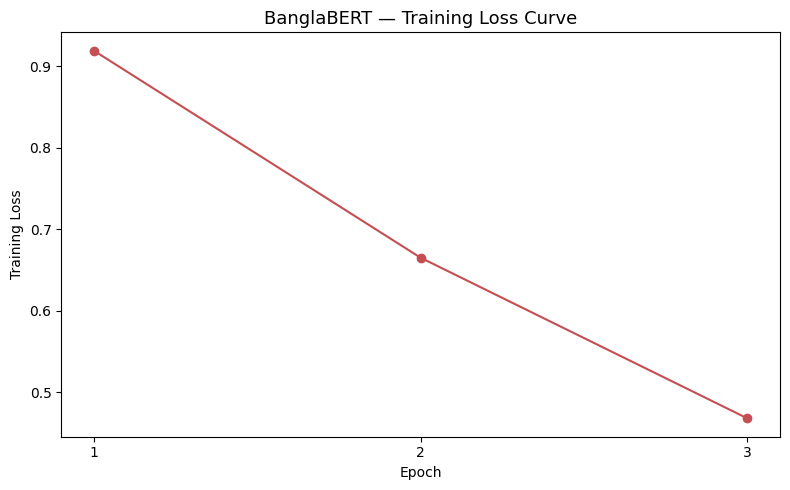

✓ Saved: fig18_bert_training_loss.png


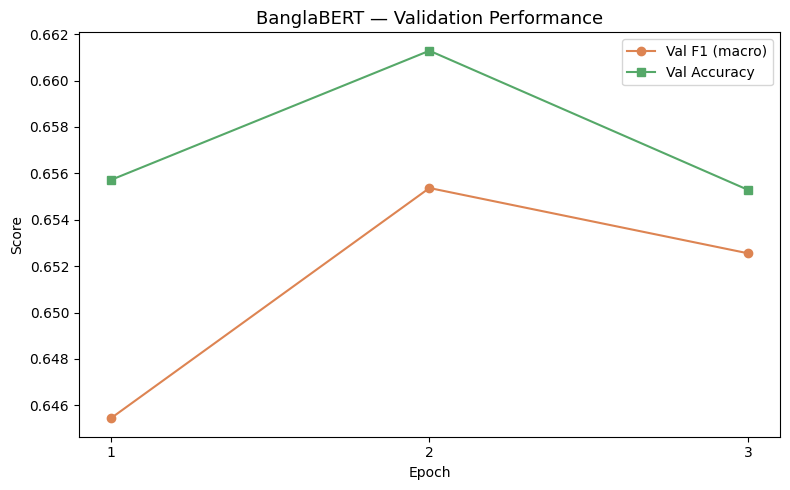

✓ Saved: fig19_bert_validation_curve.png


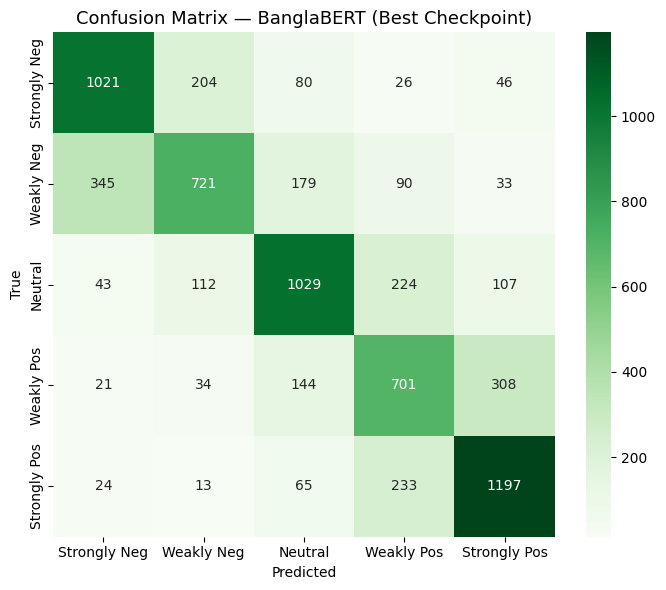

✓ Saved: fig20_cm_banglabert.png

✓ Total figures so far: 20


In [7]:
# ============================================================
# CELL 6 — TRANSFORMER BRANCH: BanglaBERT (Fig 18-20)
# ============================================================
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
from torch.cuda.amp import autocast, GradScaler

tokenizer = AutoTokenizer.from_pretrained("csebuetnlp/banglabert", use_fast=False)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    "csebuetnlp/banglabert", num_labels=5).to(device)

class BertDS(Dataset):
    def __init__(self, texts, labels, max_len=96):
        self.texts, self.labels, self.max_len = texts, labels, max_len
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        enc = tokenizer(self.texts[i], truncation=True, padding="max_length",
                         max_length=self.max_len, return_tensors="pt")
        return {k:v.squeeze(0) for k,v in enc.items()}, torch.tensor(self.labels[i])

bert_train = BertDS(train_bal["Text"].tolist(), train_bal["label"].tolist())
bert_valid = BertDS(valid_df["Text"].tolist(), y_valid.tolist())
bert_test  = BertDS(test_df["Text"].tolist(), y_test.tolist())
bt_train_loader = DataLoader(bert_train, batch_size=16, shuffle=True)
bt_valid_loader = DataLoader(bert_valid, batch_size=32)
bt_test_loader  = DataLoader(bert_test, batch_size=32)

optimizer = AdamW(bert_model.parameters(), lr=2e-5)
scaler = GradScaler(enabled=torch.cuda.is_available())

bert_losses, bert_val_f1s, bert_val_accs = [], [], []
best_f1 = 0

for epoch in range(3):
    bert_model.train()
    total_loss = 0
    for enc, yb in bt_train_loader:
        enc = {k:v.to(device) for k,v in enc.items()}
        yb = yb.to(device)
        optimizer.zero_grad()
        with autocast(enabled=torch.cuda.is_available()):
            out = bert_model(**enc, labels=yb)
            loss = out.loss
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total_loss += loss.item()
    avg_loss = total_loss/len(bt_train_loader)

    bert_model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for enc, yb in bt_valid_loader:
            enc = {k:v.to(device) for k,v in enc.items()}
            logits = bert_model(**enc).logits
            preds += logits.argmax(1).cpu().tolist()
            trues += yb.tolist()
    f1 = f1_score(trues, preds, average="macro")
    acc = accuracy_score(trues, preds)
    bert_losses.append(avg_loss); bert_val_f1s.append(f1); bert_val_accs.append(acc)
    print(f"Epoch {epoch+1}/3 | loss {avg_loss:.4f} | val F1 {f1:.4f} | val acc {acc:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        bert_model.save_pretrained(OUTPUTS/"banglabert_best")

# ── 🔧 FIX: সবচেয়ে ভালো (best) checkpoint আবার load করছি ──
# কারণ শেষ epoch সবসময় best না-ও হতে পারে (overfitting হতে পারে),
# তাই validation-এ সবচেয়ে ভালো F1 যেই epoch-এ পেয়েছিলাম, সেটাই ব্যবহার করা উচিত।
print(f"\n✓ Loading best checkpoint (val F1 = {best_f1:.4f}) for final prediction...")
bert_model = AutoModelForSequenceClassification.from_pretrained(OUTPUTS/"banglabert_best").to(device)

def get_bert_probs(loader):
    all_probs = []
    bert_model.eval()
    with torch.no_grad():
        for enc, _ in loader:
            enc = {k:v.to(device) for k,v in enc.items()}
            logits = bert_model(**enc).logits
            all_probs.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(all_probs)

P_BERT_valid = get_bert_probs(bt_valid_loader)
P_BERT_test  = get_bert_probs(bt_test_loader)
np.save(OUTPUTS/"P_BERT_valid.npy", P_BERT_valid)
np.save(OUTPUTS/"P_BERT_test.npy", P_BERT_test)
bert_pred_test = P_BERT_test.argmax(1)

# ---- Fig 18: BanglaBERT Training Loss ----
plt.figure(figsize=(8,5))
plt.plot(range(1,4), bert_losses, marker="o", color="#C44E52")
plt.title("BanglaBERT — Training Loss Curve", fontsize=13)
plt.xlabel("Epoch"); plt.ylabel("Training Loss")
plt.xticks([1,2,3])
savefig("bert_training_loss")

# ---- Fig 19: BanglaBERT Validation F1/Accuracy ----
plt.figure(figsize=(8,5))
plt.plot(range(1,4), bert_val_f1s, marker="o", label="Val F1 (macro)", color="#DD8452")
plt.plot(range(1,4), bert_val_accs, marker="s", label="Val Accuracy", color="#55A868")
plt.title("BanglaBERT — Validation Performance", fontsize=13)
plt.xlabel("Epoch"); plt.ylabel("Score"); plt.legend(); plt.xticks([1,2,3])
savefig("bert_validation_curve")

# ---- Fig 20: BanglaBERT Confusion Matrix (best checkpoint দিয়ে) ----
cm_bert = confusion_matrix(y_test, bert_pred_test)
plt.figure(figsize=(7,6))
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — BanglaBERT (Best Checkpoint)", fontsize=13)
plt.xlabel("Predicted"); plt.ylabel("True")
savefig("cm_banglabert")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 7 — Fusion + Ablation Study (Figure 21–23)

Meta-learner comparison (macro F1):
  Logistic Regression : 0.6691
  Dense NN (MLP)       : 0.6504

✓ Selected meta-learner: Logistic Regression
Fusion metrics: {'accuracy': 0.6755714285714286, 'precision_macro': 0.6699309516844302, 'recall_macro': 0.6694996552962514, 'f1_macro': 0.6691059785487574}
✓ Saved JSON: /kaggle/working/outputs/meta_learner_comparison.json
✓ Saved JSON: /kaggle/working/outputs/ablation_results.json

Ablation results table:
                                                accuracy  precision_macro  \
RF+XGB only                                      0.5030           0.5035   
CNN-BiLSTM only                                  0.5259           0.5197   
BanglaBERT only                                  0.6713           0.6653   
ML + DL                                          0.5463           0.5415   
ML + BERT                                        0.6747           0.6694   
DL + BERT                                        0.6734           0.6674   
Full Hybrid (M

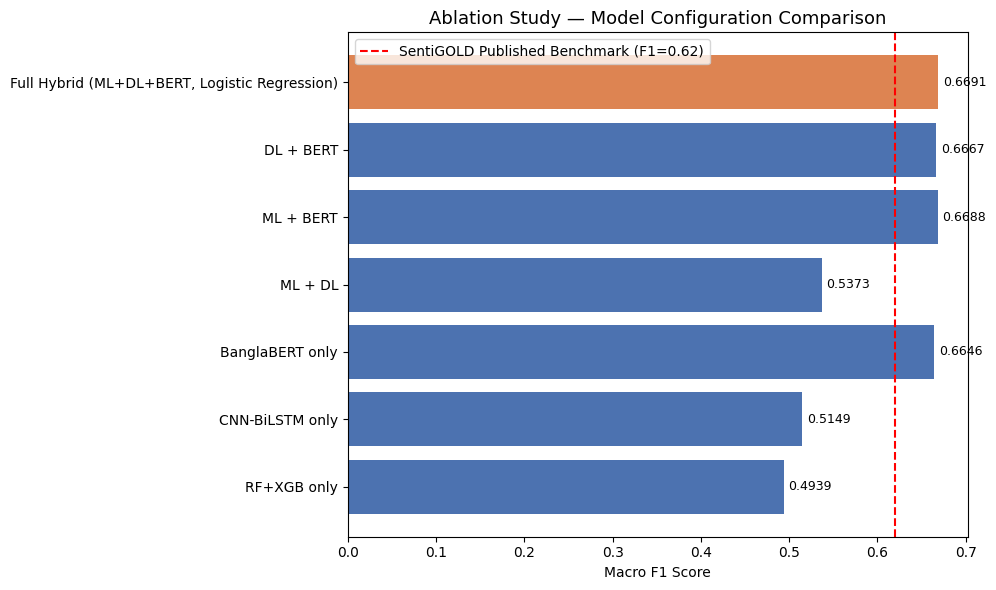

✓ Saved: fig24_ablation_study.png


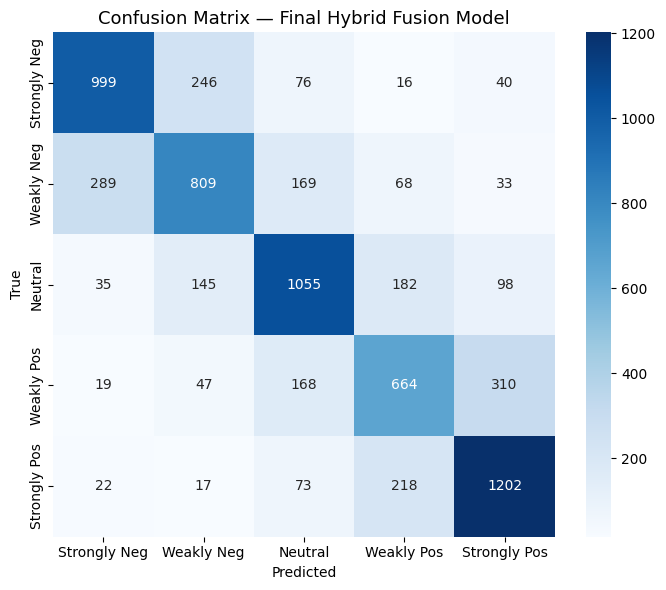

✓ Saved: fig25_cm_final_hybrid.png


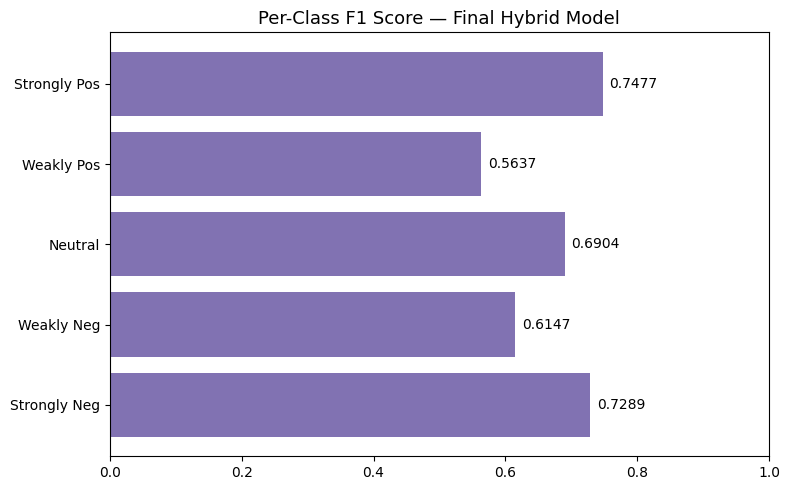

✓ Saved: fig26_hybrid_per_class_f1.png

✓ Total figures so far: 26


In [9]:
# ============================================================
# CELL 7 — FUSION + ABLATION STUDY (Fig 21-23)
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report

X_valid_fusion = np.concatenate([P_ML_valid, P_DL_valid, P_BERT_valid], axis=1)
X_test_fusion  = np.concatenate([P_ML_test,  P_DL_test,  P_BERT_test],  axis=1)

# ── Advisor fix #4: compare two meta-learners, not just Logistic Regression ──
meta_lr = LogisticRegression(max_iter=2000, random_state=SEED)
meta_lr.fit(X_valid_fusion, y_valid)
pred_lr = meta_lr.predict(X_test_fusion)
lr_metrics = metrics_dict(y_test, pred_lr)

meta_nn = MLPClassifier(hidden_layer_sizes=(32,), activation="relu", alpha=1e-3,
                         max_iter=1000, random_state=SEED, early_stopping=True)
meta_nn.fit(X_valid_fusion, y_valid)
pred_nn = meta_nn.predict(X_test_fusion)
nn_metrics = metrics_dict(y_test, pred_nn)

print("Meta-learner comparison (macro F1):")
print(f"  Logistic Regression : {lr_metrics['f1_macro']:.4f}")
print(f"  Dense NN (MLP)       : {nn_metrics['f1_macro']:.4f}")

# Pick whichever meta-learner scores higher on held-out F1; ties favour LR because on a
# 15-dim probability-fusion feature space, a linear model is easier to justify/interpret
# and less likely to overfit than a small NN.
if nn_metrics["f1_macro"] > lr_metrics["f1_macro"]:
    meta_model, meta_name = meta_nn, "Dense NN (MLP)"
    y_pred_final, fusion_metrics = pred_nn, nn_metrics
else:
    meta_model, meta_name = meta_lr, "Logistic Regression"
    y_pred_final, fusion_metrics = pred_lr, lr_metrics
print(f"\n✓ Selected meta-learner: {meta_name}")
print("Fusion metrics:", fusion_metrics)

save_json({"Logistic Regression": lr_metrics, "Dense NN (MLP)": nn_metrics, "selected": meta_name},
          OUTPUTS/"meta_learner_comparison.json")

def run_ablation(Xv, Xt, name):
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    clf.fit(Xv, y_valid)
    pred = clf.predict(Xt)
    return metrics_dict(y_test, pred)

ablation = {
    "RF+XGB only": run_ablation(P_ML_valid, P_ML_test, "ML"),
    "CNN-BiLSTM only": run_ablation(P_DL_valid, P_DL_test, "DL"),
    "BanglaBERT only": run_ablation(P_BERT_valid, P_BERT_test, "BERT"),
    "ML + DL": run_ablation(np.concatenate([P_ML_valid,P_DL_valid],1), np.concatenate([P_ML_test,P_DL_test],1), "MLDL"),
    "ML + BERT": run_ablation(np.concatenate([P_ML_valid,P_BERT_valid],1), np.concatenate([P_ML_test,P_BERT_test],1), "MLBERT"),
    "DL + BERT": run_ablation(np.concatenate([P_DL_valid,P_BERT_valid],1), np.concatenate([P_DL_test,P_BERT_test],1), "DLBERT"),
    f"Full Hybrid (ML+DL+BERT, {meta_name})": fusion_metrics,
}

# ── Advisor fix #5: save exact ablation numbers (JSON + CSV) so the paper table
# cites precise F1 values instead of numbers read off the bar chart ──
save_json(ablation, OUTPUTS/"ablation_results.json")
ablation_table = pd.DataFrame(ablation).T[["accuracy", "precision_macro", "recall_macro", "f1_macro"]]
ablation_table.to_csv(OUTPUTS/"ablation_results.csv")
print("\nAblation results table:\n", ablation_table.round(4))

# ---- Fig 21: Ablation Study Bar Chart ----
names = list(ablation.keys())
f1s = [ablation[n]["f1_macro"] for n in names]
colors = ["#4C72B0"]*6 + ["#DD8452"]
plt.figure(figsize=(10,6))
bars = plt.barh(names, f1s, color=colors)
plt.axvline(x=0.62, color="red", linestyle="--", label="SentiGOLD Published Benchmark (F1=0.62)")
for b,v in zip(bars,f1s):
    plt.text(v+0.005, b.get_y()+b.get_height()/2, f"{v:.4f}", va="center", fontsize=9)
plt.xlabel("Macro F1 Score")
plt.title("Ablation Study — Model Configuration Comparison", fontsize=13)
plt.legend()
savefig("ablation_study")

# ---- Fig 22: Final Hybrid Confusion Matrix ----
cm_final = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(7,6))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — Final Hybrid Fusion Model", fontsize=13)
plt.xlabel("Predicted"); plt.ylabel("True")
savefig("cm_final_hybrid")

# ---- Fig 23: Per-Class F1 — Final Hybrid ----
report = classification_report(y_test, y_pred_final, target_names=CLASS_NAMES, output_dict=True)
pcf1 = [report[c]["f1-score"] for c in CLASS_NAMES]
plt.figure(figsize=(8,5))
bars = plt.barh(CLASS_NAMES, pcf1, color="#8172B2")
plt.xlim(0,1)
for b,v in zip(bars,pcf1):
    plt.text(v+0.01, b.get_y()+b.get_height()/2, f"{v:.4f}", va="center")
plt.title("Per-Class F1 Score — Final Hybrid Model", fontsize=13)
savefig("hybrid_per_class_f1")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 8 — Extra Comparison + XAI Figures (Figure 24–26)

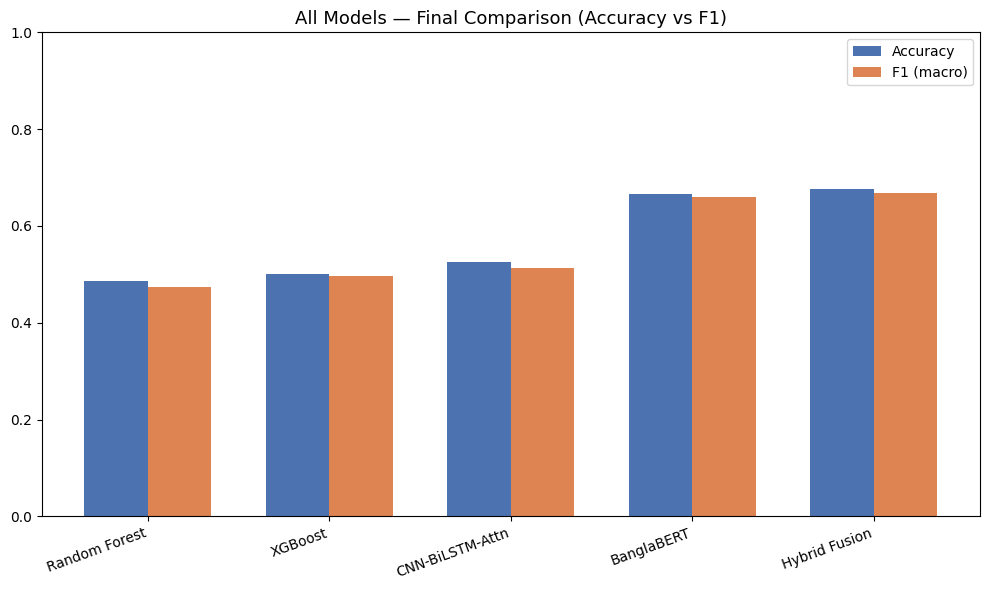

✓ Saved: fig27_all_models_comparison.png


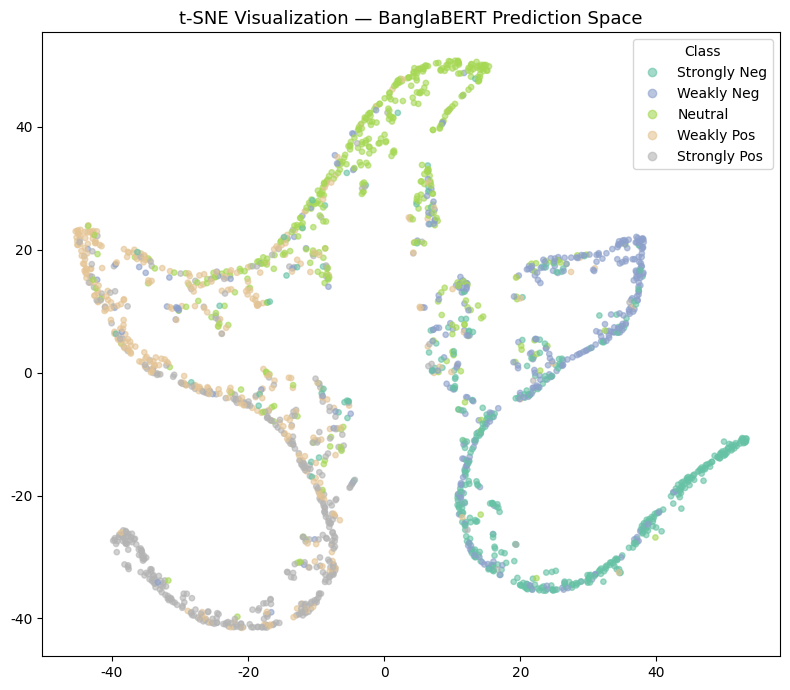

✓ Saved: fig28_tsne_banglabert.png


/tmp/ipykernel_58/2448674758.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  domain_f1 = test_df_full.groupby("Domain").apply(


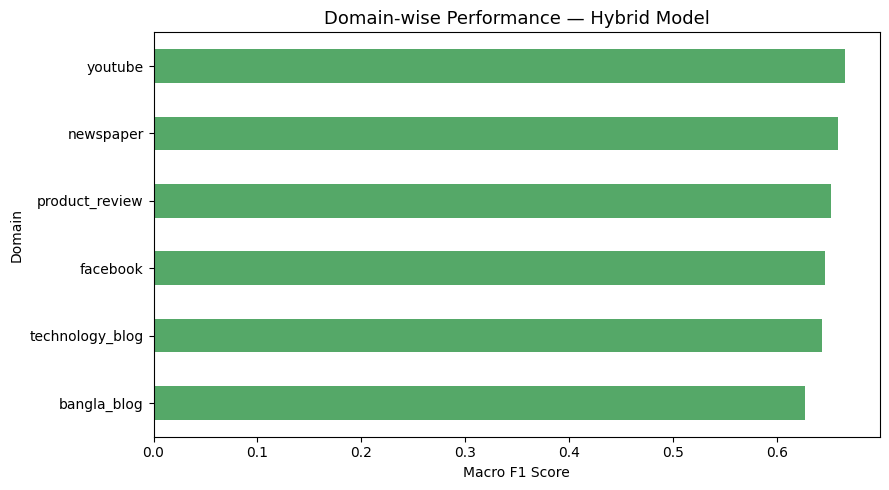

✓ Saved: fig29_domain_wise_performance.png

🎉 FINAL TOTAL FIGURES SAVED: 29
All figure you will find: /kaggle/working/figures


In [10]:
# ============================================================
# CELL 8 — EXTRA COMPARISON + XAI FIGURES (Fig 24-26)
# ============================================================
from sklearn.manifold import TSNE

# ---- Fig 24: All Models Comparison (Accuracy + F1) ----
all_models = {
    "Random Forest": rf_metrics,
    "XGBoost": xgb_metrics,
    "CNN-BiLSTM-Attn": metrics_dict(y_test, dl_pred_test),
    "BanglaBERT": metrics_dict(y_test, bert_pred_test),
    "Hybrid Fusion": fusion_metrics,
}
names = list(all_models.keys())
accs = [all_models[n]["accuracy"] for n in names]
f1s2 = [all_models[n]["f1_macro"] for n in names]
x = np.arange(len(names)); width=0.35
plt.figure(figsize=(10,6))
plt.bar(x-width/2, accs, width, label="Accuracy", color="#4C72B0")
plt.bar(x+width/2, f1s2, width, label="F1 (macro)", color="#DD8452")
plt.xticks(x, names, rotation=20, ha="right")
plt.ylim(0,1)
plt.title("All Models — Final Comparison (Accuracy vs F1)", fontsize=13)
plt.legend()
savefig("all_models_comparison")

# ---- Fig 25: t-SNE of BanglaBERT Probability Space ----
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
sample_n = min(2000, len(P_BERT_test))
idx = np.random.choice(len(P_BERT_test), sample_n, replace=False)
tsne_out = tsne.fit_transform(P_BERT_test[idx])
plt.figure(figsize=(8,7))
scatter = plt.scatter(tsne_out[:,0], tsne_out[:,1], c=y_test[idx], cmap="Set2", alpha=0.6, s=15)
handles,_ = scatter.legend_elements()
plt.legend(handles, CLASS_NAMES, title="Class", loc="best")
plt.title("t-SNE Visualization — BanglaBERT Prediction Space", fontsize=13)
savefig("tsne_banglabert")

# ---- Fig 26: Domain-wise Performance (Hybrid Model) ----
if "Domain" in df.columns:
    test_domains = df.loc[test_df.index, "Domain"] if test_df.index.isin(df.index).all() else None
    # domain info merge করে নেই (ID না থাকলে index দিয়ে merge করা কঠিন, তাই raw থেকে merge করা ভালো)
    test_df_full = test_df.copy()
    test_df_full["pred"] = y_pred_final
    test_df_full["true"] = y_test
    if "Domain" in test_df_full.columns:
        domain_f1 = test_df_full.groupby("Domain").apply(
            lambda g: f1_score(g["true"], g["pred"], average="macro"))
        plt.figure(figsize=(9,5))
        domain_f1.sort_values().plot(kind="barh", color="#55A868")
        plt.xlabel("Macro F1 Score")
        plt.title("Domain-wise Performance — Hybrid Model", fontsize=13)
        savefig("domain_wise_performance")

print(f"\n🎉 FINAL TOTAL FIGURES SAVED: {fig_count}")
print(f"All figure you will find: {FIGS}")

Cell 10 — Statistical Robustness: Bootstrap Confidence Interval (Figure 27)

Hybrid Model — Macro F1: 0.6691
95% Bootstrap Confidence Interval: [0.6581, 0.6798]
Standard Deviation: 0.0057


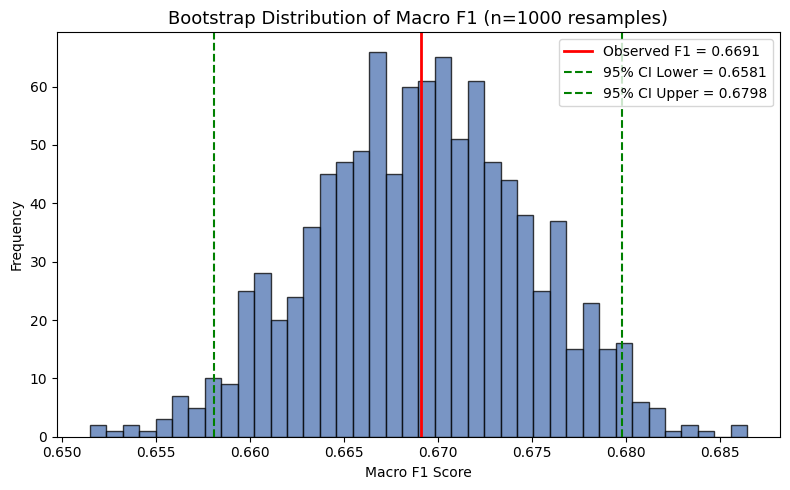

✓ Saved: fig30_bootstrap_f1_distribution.png

✓ Total figures so far: 30


In [11]:
# ============================================================
# CELL 10 — BOOTSTRAP CONFIDENCE INTERVAL (Fig 27)
# ============================================================
n_bootstrap = 1000
rng = np.random.default_rng(SEED)
boot_f1s = []
n = len(y_test)

for _ in range(n_bootstrap):
    idx = rng.choice(n, size=n, replace=True)
    boot_f1s.append(f1_score(y_test[idx], y_pred_final[idx], average="macro"))

boot_f1s = np.array(boot_f1s)
ci_lower, ci_upper = np.percentile(boot_f1s, [2.5, 97.5])
print(f"Hybrid Model — Macro F1: {fusion_metrics['f1_macro']:.4f}")
print(f"95% Bootstrap Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Standard Deviation: {boot_f1s.std():.4f}")

# ---- Fig 27: Bootstrap Distribution ----
plt.figure(figsize=(8,5))
plt.hist(boot_f1s, bins=40, color="#4C72B0", edgecolor="black", alpha=0.75)
plt.axvline(fusion_metrics["f1_macro"], color="red", linestyle="-", linewidth=2,
            label=f"Observed F1 = {fusion_metrics['f1_macro']:.4f}")
plt.axvline(ci_lower, color="green", linestyle="--", label=f"95% CI Lower = {ci_lower:.4f}")
plt.axvline(ci_upper, color="green", linestyle="--", label=f"95% CI Upper = {ci_upper:.4f}")
plt.title("Bootstrap Distribution of Macro F1 (n=1000 resamples)", fontsize=13)
plt.xlabel("Macro F1 Score")
plt.ylabel("Frequency")
plt.legend()
savefig("bootstrap_f1_distribution")

print(f"\n✓ Total figures so far: {fig_count}")

Cell 11 — Error Analysis (Figure 28)

Total test samples: 7000
Misclassified: 2271 (32.4%)

Top-10 Confusion Pairs (True → Predicted):
true_label    pred_label  
Weakly Pos    Strongly Pos    310
Weakly Neg    Strongly Neg    289
Strongly Neg  Weakly Neg      246
Strongly Pos  Weakly Pos      218
Neutral       Weakly Pos      182
Weakly Neg    Neutral         169
Weakly Pos    Neutral         168
Neutral       Weakly Neg      145
              Strongly Pos     98
Strongly Neg  Neutral          76
dtype: int64


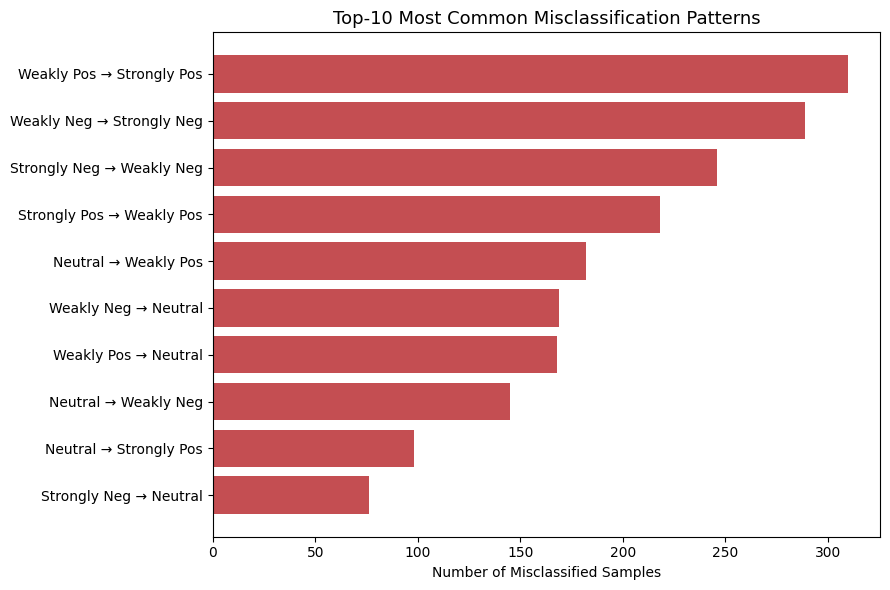

✓ Saved: fig31_top_confusion_pairs.png

--- ৫টা Misclassification Example (Discussion section-এ ব্যবহার করার জন্য) ---

Text: জানুন.শিখুন. উপলব্ধি করুন এবং তারপর মন্তব্য করুন।
  True: Weakly Pos  |  Predicted: Neutral

Text: নরম লেখা লেখার জন্য পড়তে হবে নরম লেখা, পরতে হবে লুঙ্গী
  True: Weakly Pos  |  Predicted: Neutral

Text: বেদে সমাজে নারী-পুরুষ উভয়ই সমানতালে খাটে উপার্জনের জন্য।
  True: Weakly Pos  |  Predicted: Strongly Pos

Text: অনেকে সস্তা সুনাম নিয়েই বিজি দেখি এটাতে আসলে আপনাকে সম্মান করে বলা।
  True: Strongly Pos  |  Predicted: Weakly Pos

Text: আমার ধারণা লেখাপড়ার আসল উদ্দেশ্য কী হওয়া উচিৎ সেটা বোঝার জন্যে আলবার্ট আইনস্টাইনের জীবনের কয়েকটা 
  True: Weakly Pos  |  Predicted: Neutral

✓ Total figures so far: 31


In [12]:
# ============================================================
# CELL 11 — ERROR ANALYSIS (Fig 28)
# ============================================================
misclassified = test_df.reset_index(drop=True).copy()
misclassified["true_label"]  = [CLASS_NAMES[i] for i in y_test]
misclassified["pred_label"]  = [CLASS_NAMES[i] for i in y_pred_final]
misclassified["correct"]     = (y_test == y_pred_final)

wrong = misclassified[~misclassified["correct"]]
print(f"Total test samples: {len(misclassified)}")
print(f"Misclassified: {len(wrong)} ({len(wrong)/len(misclassified)*100:.1f}%)")

# ---- সবচেয়ে বেশি কোন pair-এ ভুল হচ্ছে (confusion pairs) ----
error_pairs = wrong.groupby(["true_label","pred_label"]).size().sort_values(ascending=False).head(10)
print("\nTop-10 Confusion Pairs (True → Predicted):")
print(error_pairs)

# ---- Fig 28: Top Confusion Pairs Bar Chart ----
pair_labels = [f"{t} → {p}" for (t,p) in error_pairs.index]
plt.figure(figsize=(9,6))
plt.barh(pair_labels[::-1], error_pairs.values[::-1], color="#C44E52")
plt.xlabel("Number of Misclassified Samples")
plt.title("Top-10 Most Common Misclassification Patterns", fontsize=13)
savefig("top_confusion_pairs")

# ---- কিছু ভুল হওয়া উদাহরণ vertical print করা (thesis-এর appendix/discussion-এ কাজে লাগবে) ----
print("\n--- ৫টা Misclassification Example (Discussion section-এ ব্যবহার করার জন্য) ---")
sample_errors = wrong.sample(min(5, len(wrong)), random_state=SEED)
for i, row in sample_errors.iterrows():
    print(f"\nText: {row['Text'][:100]}")
    print(f"  True: {row['true_label']}  |  Predicted: {row['pred_label']}")

print(f"\n✓ Total figures so far: {fig_count}")

New code

In [13]:
from scipy.stats import wilcoxon
# per-sample correctness arrays (0/1) already exist: 
bert_correct = (y_test == bert_pred_test).astype(int)
hybrid_correct = (y_test == y_pred_final).astype(int)
stat, p = wilcoxon(hybrid_correct, bert_correct)
print("Wilcoxon p-value:", p)

# Paired bootstrap on the difference
diffs = []
for _ in range(1000):
    idx = rng.choice(len(y_test), size=len(y_test), replace=True)
    diffs.append(f1_score(y_test[idx], y_pred_final[idx], average="macro")
                - f1_score(y_test[idx], bert_pred_test[idx], average="macro"))
print("Paired bootstrap 95% CI on (Hybrid - BERT):", np.percentile(diffs, [2.5, 97.5]))

Wilcoxon p-value: 0.0023187814543345845
Paired bootstrap 95% CI on (Hybrid - BERT): [0.00343823 0.01469084]


All Figure download

In [14]:
# ============================================================
# CELL — DOWNLOAD ALL FIGURES AS ZIP (Kaggle version)
# ============================================================
import zipfile
import os

zip_path = ROOT / "all_figures.zip"

png_files = sorted(FIGS.glob("*.png"))

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for fig in png_files:
        zipf.write(fig, arcname=fig.name)
        print(f"✅ Added: {fig.name}")

print(f"\n📦 ZIP Ready: {zip_path}")
print(f"📊 Total {len(png_files)} figure zip")
print("\n👉 ডাউনলোড করতে: ডানপাশের 'Output' প্যানেলে যান → /kaggle/working → all_figures.zip এর পাশে ⋮ (তিন ডট) → Download")

✅ Added: fig01_class_distribution.png
✅ Added: fig02_domain_distribution.png
✅ Added: fig03_text_length_distribution.png
✅ Added: fig04_textlen_by_class.png
✅ Added: fig05_wordcloud_positive.png
✅ Added: fig06_wordcloud_negative.png
✅ Added: fig07_train_val_test_split.png
✅ Added: fig08_oversampling_before_after.png
✅ Added: fig09_cm_random_forest.png
✅ Added: fig10_cm_xgboost.png
✅ Added: fig11_ml_models_comparison.png
✅ Added: fig12_rf_feature_importance.png
✅ Added: fig13_rf_per_class_f1.png
✅ Added: fig14_dl_training_loss.png
✅ Added: fig15_dl_validation_curve.png
✅ Added: fig16_cm_cnn_bilstm.png
✅ Added: fig17_attention_heatmap_example.png
✅ Added: fig18_bert_training_loss.png
✅ Added: fig19_bert_validation_curve.png
✅ Added: fig20_cm_banglabert.png
✅ Added: fig21_ablation_study.png
✅ Added: fig22_cm_final_hybrid.png
✅ Added: fig23_hybrid_per_class_f1.png
✅ Added: fig24_ablation_study.png
✅ Added: fig25_cm_final_hybrid.png
✅ Added: fig26_hybrid_per_class_f1.png
✅ Added: fig27_all_